In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

% matplotlib inline

In [2]:
def show_images(images):
    for name, image in images:
        cv.imshow(name, image)
    cv.waitKey(0)
    cv.destroyAllWindows()


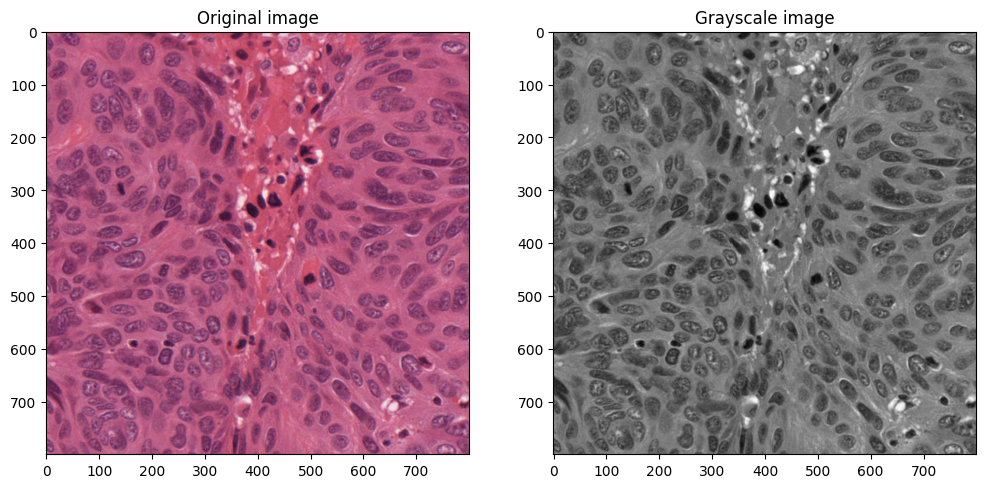

In [96]:
# load image
file = 'images/TCGA-18-5592-01Z-00-DX1.tif'
img = cv.imread(file)

# scale image
scaling = 0.8
img = cv.resize(img, None, fx=scaling, fy=scaling)

# convert to grayscale and RGB
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# show images
plt.figure(figsize=(12, 12))
plt.subplot(1, 2, 1)
plt.title('Original image')
plt.imshow(rgb_img)
plt.subplot(1, 2, 2)
plt.title('Grayscale image')
plt.imshow(gray, cmap='gray')
plt.show()

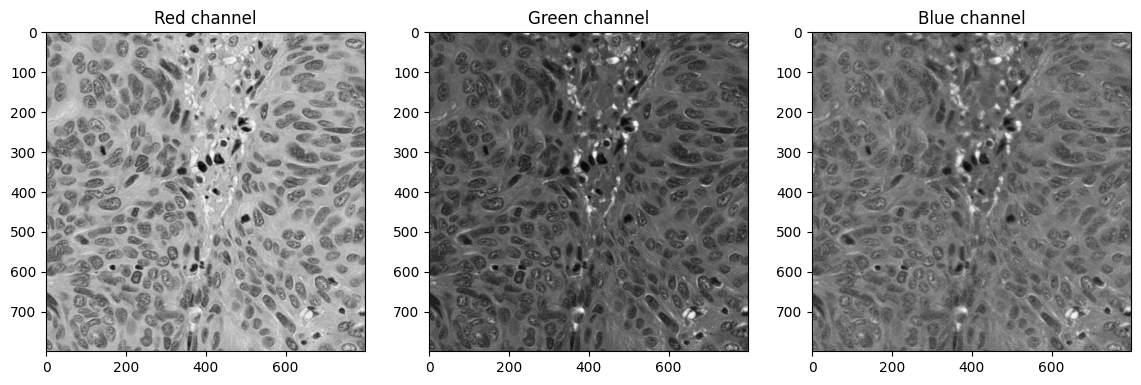

In [97]:
# split channels to RGB
b, g, r = cv.split(img)

# show RGB channels
plt.figure(figsize=(14, 14))
plt.subplot(1, 3, 1)
plt.title('Red channel')
plt.imshow(r, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('Green channel')
plt.imshow(g, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('Blue channel')
plt.imshow(b, cmap='gray')
plt.show()

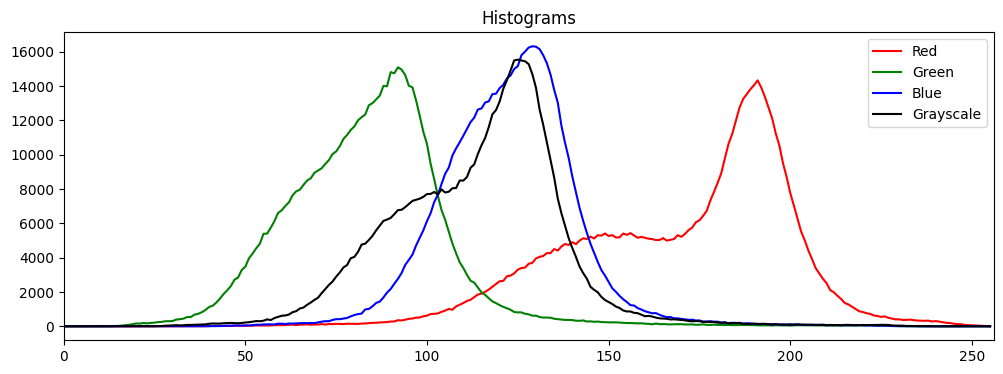

In [113]:
# create histograms
hist_r = cv.calcHist([r], [0], None, [256], [0, 256])
hist_g = cv.calcHist([g], [0], None, [256], [0, 256])
hist_b = cv.calcHist([b], [0], None, [256], [0, 256])
hist_gray = cv.calcHist([gray], [0], None, [256], [0, 256])

# plot histograms in one figure
plt.figure(figsize=(12, 4))
plt.title('Histograms')
plt.plot(hist_r, color='r')
plt.plot(hist_g, color='g')
plt.plot(hist_b, color='b')
plt.plot(hist_gray, color='k')
plt.xlim([0, 256])
plt.legend(['Red', 'Green', 'Blue', 'Grayscale'], loc='upper right')
plt.show()

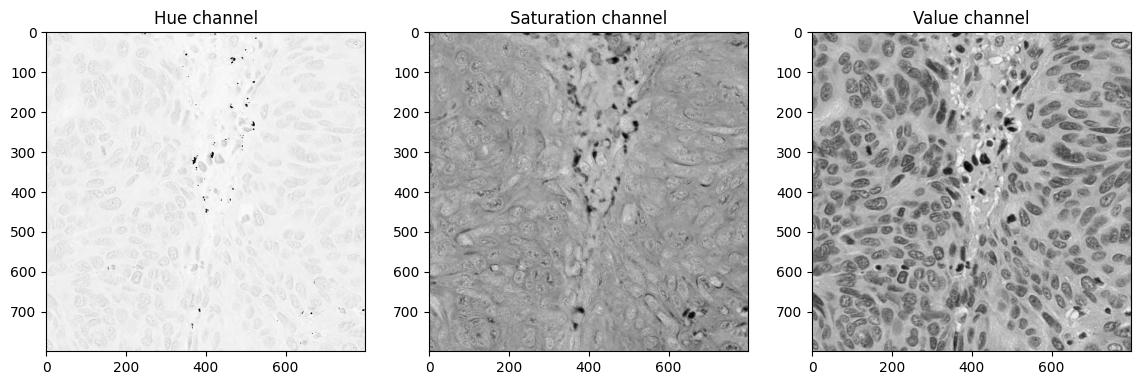

In [99]:
# convert to HSV
hsv_img = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# split channels
h, s, v = cv.split(hsv_img)

# show hsv channels
plt.figure(figsize=(14, 14))
plt.subplot(1, 3, 1)
plt.title('Hue channel')
plt.imshow(h, cmap='gray')
plt.subplot(1, 3, 2)
plt.title('Saturation channel')
plt.imshow(s, cmap='gray')
plt.subplot(1, 3, 3)
plt.title('Value channel')
plt.imshow(v, cmap='gray')
plt.show()

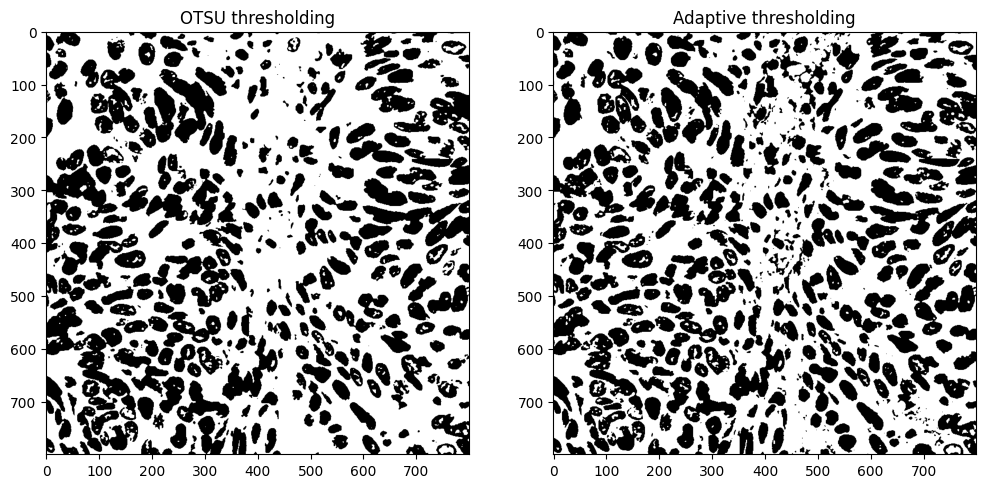

In [117]:
blur = cv.GaussianBlur(v, (5, 5), 0)

# OTSU thresholding
ret, otsu_thresh = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Adaptive thresholding
adap_thresh = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 175, 2)

# plot images
plt.figure(figsize=(12, 12))
plt.subplot(1, 2, 1)
plt.title('OTSU thresholding')
plt.imshow(otsu_thresh, cmap='gray')
plt.subplot(1, 2, 2)
plt.title('Adaptive thresholding')
plt.imshow(adap_thresh, cmap='gray')
plt.show()

In [118]:
show_images([
    ('Original image', img),
    ('OTSU thresholding', otsu_thresh),
    ('Adaptive thresholding', adap_thresh),
])

## Method 1

Number of contours: 247


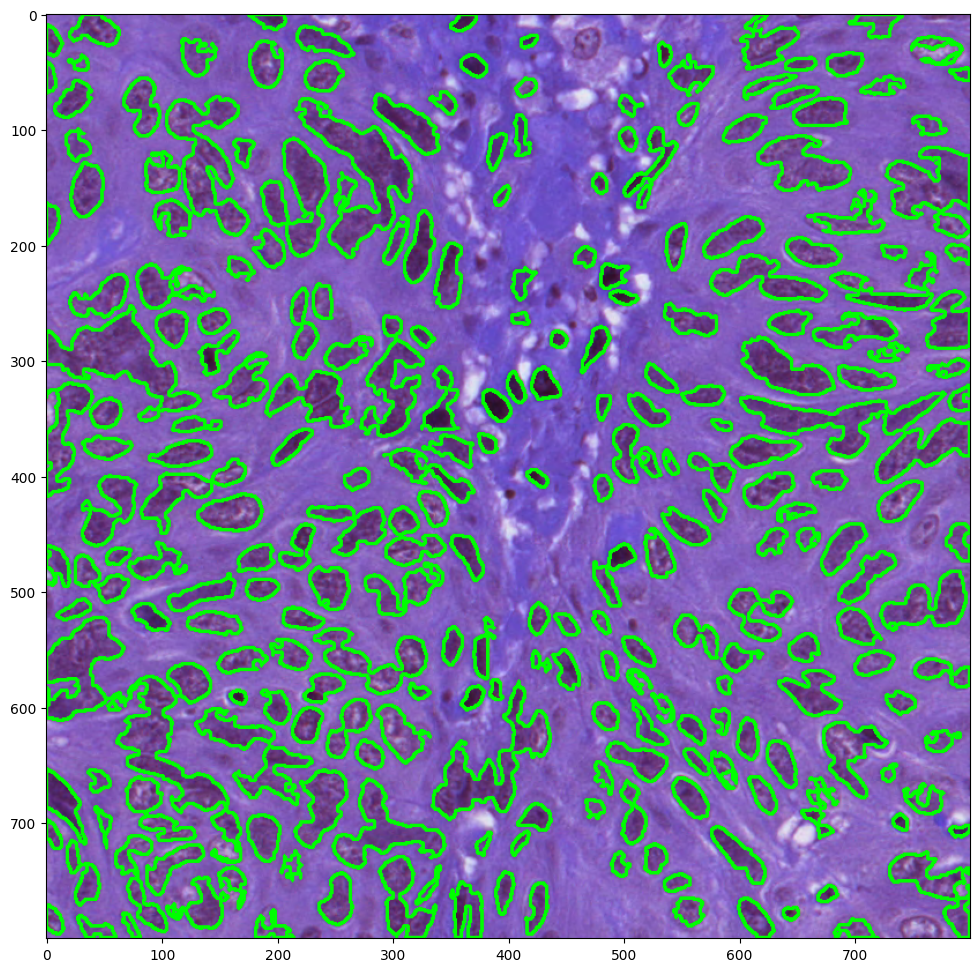

In [133]:
thresh = otsu_thresh

# morphological closing
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
closing = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel)

# dilate image
kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
dilate = cv.dilate(closing, kernel, iterations=1)

# morphological opening
kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
opening = cv.morphologyEx(dilate, cv.MORPH_OPEN, kernel, iterations=2)

# invert image
inverted = cv.bitwise_not(dilate)

# find contours
contours, hierarchy = cv.findContours(inverted, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# filter contours
contours = [c for c in contours if cv.contourArea(c) > 100]

# draw contours
contour_img = img.copy()
cv.drawContours(contour_img, contours, -1, (0, 255, 0), 2)
print(f'Number of contours: {len(contours)}')

# plot images
plt.figure(figsize=(12, 12))
plt.imshow(contour_img, cmap='gray')

In [126]:
show_images([
    ('Thresholded image', thresh),
    ('Morphological closing', closing),
    ('Dilated image', dilate),
    ('Morphological opening', opening),
    # ('Inverted image', inverted),
    # ('Image with contours', contour_img),
])

## Method 2